In [1]:
print("Hi")

Hi


In [1]:
# Cell 1 — Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')

print("All imports successful!")

ModuleNotFoundError: No module named 'pandas'

In [2]:
# Cell 2 — Load Dataset
df = pd.read_csv('phishing_email.csv')
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
df.head()

NameError: name 'pd' is not defined

## Class Distribution
### We analyze class distribution to check for imbalance...

Label counts:
label
1    42891
0    39595
Name: count, dtype: int64

Label percentages:
label
1    51.997915
0    48.002085
Name: proportion, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

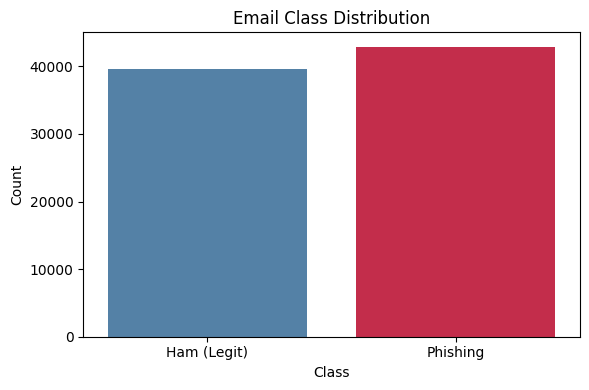

In [8]:
# Cell 3 — Class Distribution
print("Label counts:")
print(df['label'].value_counts())
print("\nLabel percentages:")
print(df['label'].value_counts(normalize=True) * 100)

# Plot
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df, palette=['steelblue', 'crimson'])
plt.xticks([0,1], ['Ham (Legit)', 'Phishing'])
plt.title('Email Class Distribution')
plt.ylabel('Count')
plt.xlabel('Class')
plt.tight_layout()
plt.show


## Email Length Distribution
We analyze the length of emails in each class to understand if phishing emails tend to be longer or shorter than legitimate emails.

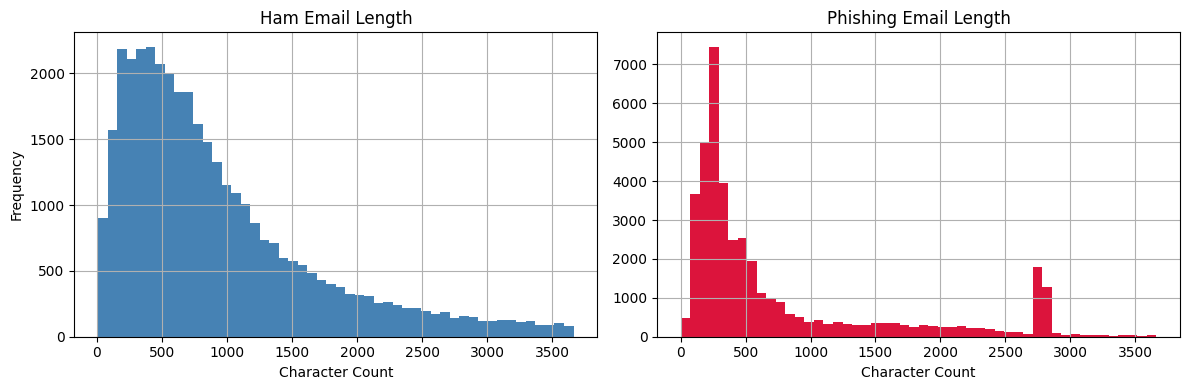


Average email length by class:
Ham (Legit):  1536 characters
Phishing:     1060 characters


In [16]:
# Cell 4 — Email Length Distribution 
df['text_length'] = df['text_combined'].str.len()

# Cap at 95th percentile to remove outliers
cap = df['text_length'].quantile(0.95)
df_capped = df[df['text_length'] <= cap]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_capped[df_capped['label']==0]['text_length'].hist(bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Ham Email Length')
axes[0].set_xlabel('Character Count')
axes[0].set_ylabel('Frequency')

df_capped[df_capped['label']==1]['text_length'].hist(bins=50, ax=axes[1], color='crimson')
axes[1].set_title('Phishing Email Length')
axes[1].set_xlabel('Character Count')

plt.tight_layout()
plt.show()

print("\nAverage email length by class:")
print(f"Ham (Legit):  {df[df['label']==0]['text_length'].mean():.0f} characters")
print(f"Phishing:     {df[df['label']==1]['text_length'].mean():.0f} characters")

## Missing Values Check
We check for missing values in the dataset to ensure data quality before training.

In [18]:
# Cell 5 — Missing Values
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing: {df.isnull().sum().sum()}")
print(f"Total rows: {len(df)}")

Missing values per column:
text_combined    0
label            0
text_length      0
dtype: int64

Total missing: 0
Total rows: 82486


## Missing Values Check
No missing values were found across all columns, confirming the dataset is clean and ready for training.

## Most Common Words by Class
We visualize the most frequent words in phishing vs ham emails using word clouds.

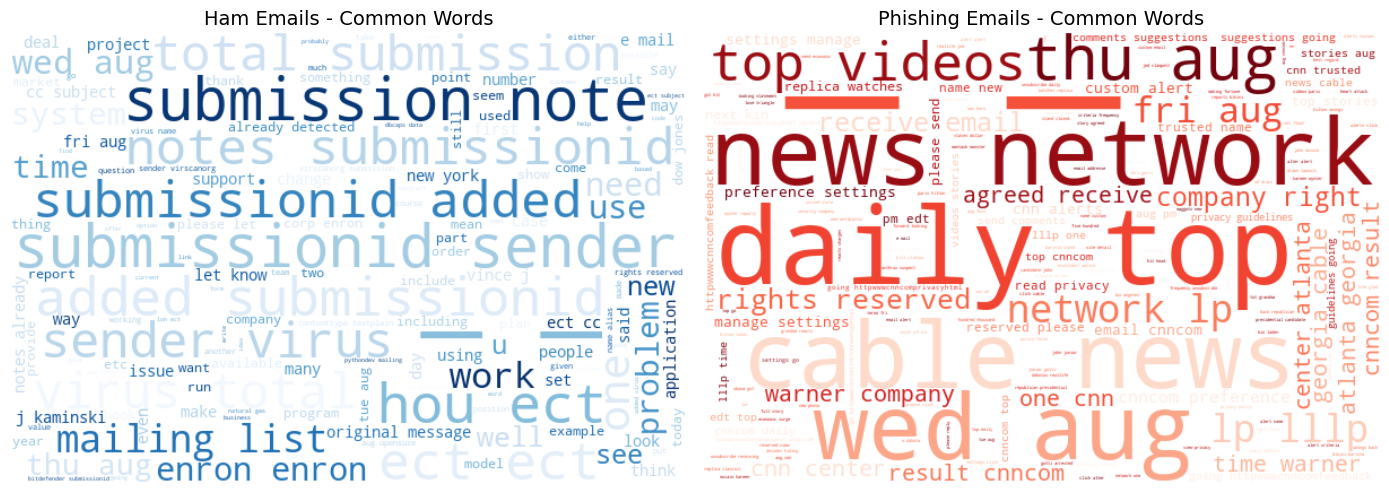

In [20]:
# Cell 6 — Word Clouds
ham_text = ' '.join(df[df['label']==0]['text_combined'].astype(str))
phish_text = ' '.join(df[df['label']==1]['text_combined'].astype(str))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

wordcloud_ham = WordCloud(width=600, height=400, background_color='white', colormap='Blues').generate(ham_text)
axes[0].imshow(wordcloud_ham, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Ham Emails - Common Words', fontsize=14)

wordcloud_phish = WordCloud(width=600, height=400, background_color='white', colormap='Reds').generate(phish_text)
axes[1].imshow(wordcloud_phish, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Phishing Emails - Common Words', fontsize=14)

plt.tight_layout()
plt.show()

## Top 20 Most Frequent Words by Class
Word frequency bar charts provide a clearer quantitative view of the most common terms in each class.

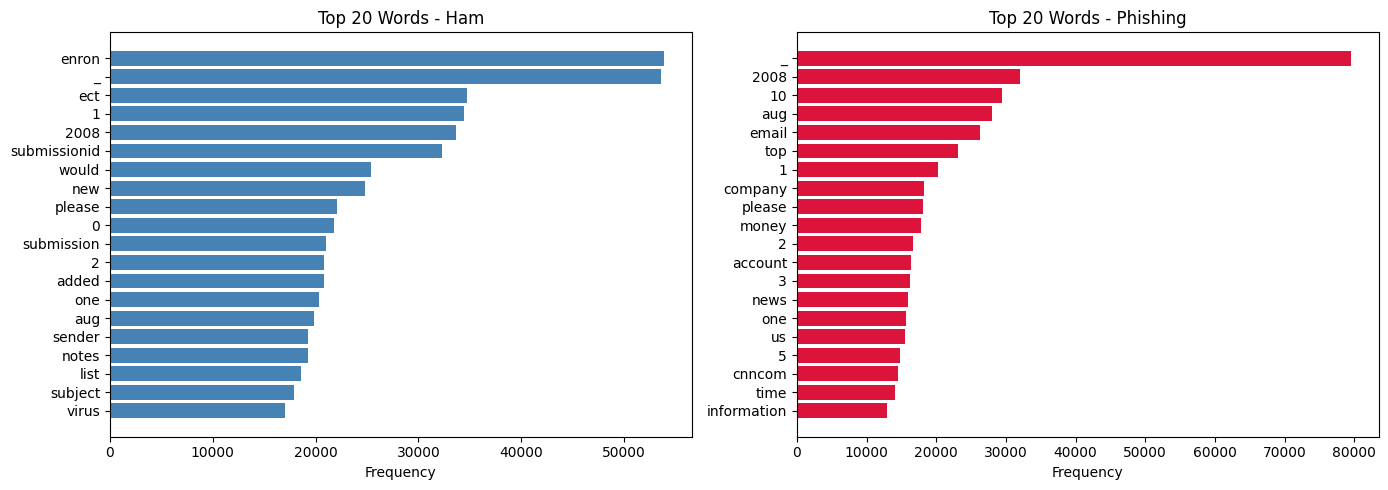

In [21]:
# Cell 7 — Top 20 words bar chart
from collections import Counter

def get_top_words(texts, n=20):
    words = ' '.join(texts).split()
    return Counter(words).most_common(n)

ham_words = get_top_words(df[df['label']==0]['text_combined'].astype(str))
phish_words = get_top_words(df[df['label']==1]['text_combined'].astype(str))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh([w[0] for w in ham_words[::-1]], [w[1] for w in ham_words[::-1]], color='steelblue')
axes[0].set_title('Top 20 Words - Ham')
axes[0].set_xlabel('Frequency')

axes[1].barh([w[0] for w in phish_words[::-1]], [w[1] for w in phish_words[::-1]], color='crimson')
axes[1].set_title('Top 20 Words - Phishing')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.show()

## Top 20 Meaningful Words by Class
Stopwords and numbers are removed to reveal truly distinctive terms per class.

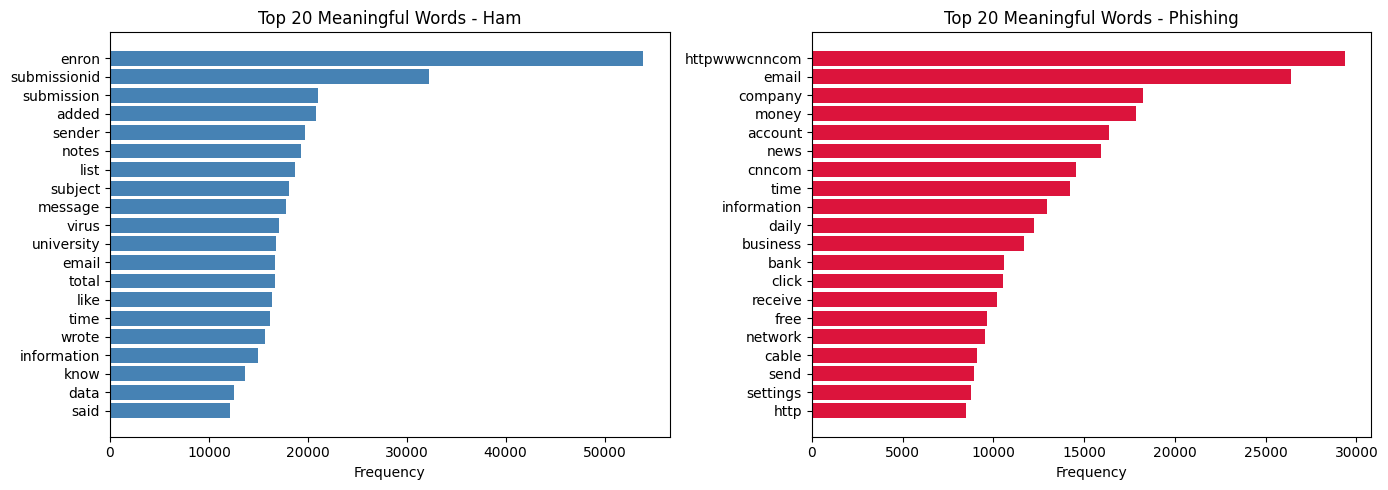

In [24]:
# Cell 8 — Top 20 clean words
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def get_clean_top_words(texts, n=20):
    all_words = []
    for text in texts:
        words = re.findall(r'[a-zA-Z]{4,}', str(text).lower())
        words = [w for w in words if w not in ENGLISH_STOP_WORDS]
        all_words.extend(words)
    return Counter(all_words).most_common(n)

ham_words = get_clean_top_words(df[df['label']==0]['text_combined'])
phish_words = get_clean_top_words(df[df['label']==1]['text_combined'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh([w[0] for w in ham_words[::-1]], [w[1] for w in ham_words[::-1]], color='steelblue')
axes[0].set_title('Top 20 Meaningful Words - Ham')
axes[0].set_xlabel('Frequency')

axes[1].barh([w[0] for w in phish_words[::-1]], [w[1] for w in phish_words[::-1]], color='crimson')
axes[1].set_title('Top 20 Meaningful Words - Phishing')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.show()

## EDA Summary - Email Dataset
Key findings from the exploratory data analysis:
- The dataset contains 82,486 emails, nearly balanced between ham (48%) and phishing (52%)
- No missing values were found, confirming data quality
- Ham emails are longer on average (1,536 chars) vs phishing emails (1,060 chars)
- Phishing emails frequently contain words like "account", "money", "information" suggesting financial manipulation
- Ham emails are dominated by organizational terms like "enron", "submission", "sender"
- These findings justify the use of TF-IDF with Logistic Regression for classification